In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from scipy.spatial.distance import mahalanobis 
from scipy.stats import chi2 

DATASET

In [2]:
rng = np.random.default_rng(seed=353)  
n   = 150 

study = rng.normal(6, 1.5, n).clip(2, 11).round(1) 
score = np.clip(8*study + rng.normal(0, 10, n), 10, 100).round(1) 

extras = pd.DataFrame({"study_hours":[12.0, 2.5, 9.0], 
"exam_score" :[94.0,88.0,18.0]}) 

df = pd.concat([pd.DataFrame({"study_hours":study,"exam_score":score}), 
extras], ignore_index=True) 

df.to_csv("student_performance.csv", index=False) 



B.1  Load and Explore 

In [3]:
df.describe()

,study_hours,exam_score
count,153.000000,153.000000
mean,5.992810,48.073856
std,1.615635,16.741784
min,2.500000,13.900000
25%,4.900000,36.000000
50%,5.800000,47.200000
75%,7.000000,58.800000
max,12.000000,94.000000


for study hours the mean is above median by 0.19

for exam scores the mean is above the median by 0.87

thus, the exam score column has larger gap 


.

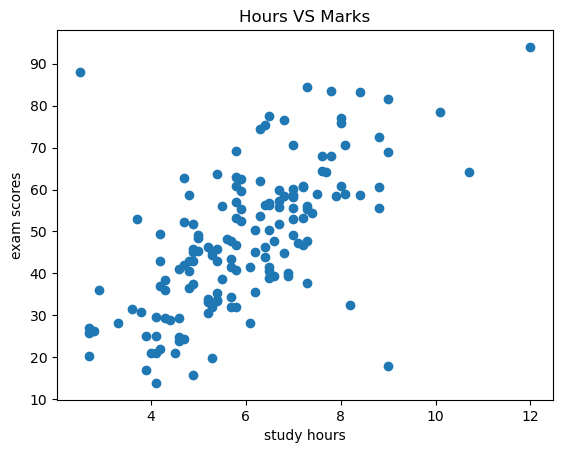

In [4]:
plt.scatter(df["study_hours"],df["exam_score"])

plt.xlabel("study hours")
plt.ylabel("exam scores")
plt.title("Hours VS Marks")

plt.show()

i can see a positive trend like as the hour increase the marks also increase

but at some points i can see unusual trend like :

(2hr, 87 marks) , (9hr, 18 marks), (12hr, 93 marks)


.

B.2  Univariate Outlier Detection 

In [5]:
Q1 = df[["study_hours", "exam_score"]].quantile(0.25)
Q3 = df[["study_hours", "exam_score"]].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound)
print(upper_bound)

study_hours    1.75
exam_score     1.80
dtype: float64
study_hours    10.15
exam_score     93.00
dtype: float64


In [6]:
outlier = (
    (df["study_hours"] < lower_bound["study_hours"]) |
    (df["study_hours"] > upper_bound["study_hours"]) |
    (df["exam_score"] < lower_bound["exam_score"]) |
    (df["exam_score"] > upper_bound["exam_score"])
)

print(df[outlier])

     study_hours  exam_score
87          10.7        64.2
150         12.0        94.0


C:\Users\shrus\AppData\Local\Temp\ipykernel_31156\2539084710.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


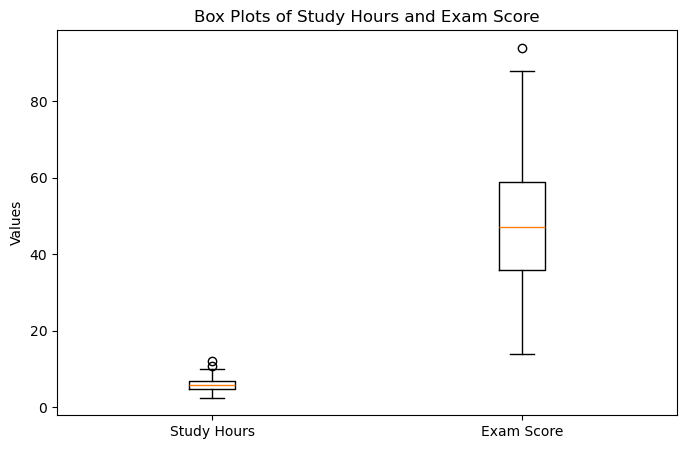

In [7]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [df["study_hours"], df["exam_score"]],
    labels=["Study Hours", "Exam Score"]
)

plt.title("Box Plots of Study Hours and Exam Score")
plt.ylabel("Values")

plt.show()

In [8]:
df.loc[[150, 151, 152]]

,study_hours,exam_score
150,12.0,94.0
151,2.5,88.0
152,9.0,18.0


.

| Index | study_hours flagged? | exam_score flagged? | Interpretation |
|---|---|---|---|
| 150 | Yes | Yes | univariate outlier in both columns |
| 151 | No | No | not caught univariately |
| 152 | No | No | not caught univariately |

.

B.3  Euclidean Distance from Centroid

In [9]:
x = df[["study_hours", "exam_score"]]

z = (x - x.mean()) / x.std(ddof=0)

print(z)

     study_hours  exam_score
0       0.625449    0.061494
1      -0.492323   -0.849396
2       2.550500    1.829339
3       0.998039    0.978376
4      -1.485898   -0.987228
..           ...         ...
148     1.743221    0.457012
149     0.749646    0.762639
150     3.730370    2.752214
151    -2.168981    2.392652
152     1.867418   -1.802235

[153 rows x 2 columns]


In [10]:
euclid = (z["study_hours"]**2 + z["exam_score"]**2)**0.5

print(euclid)

0      0.628465
1      0.981761
2      3.138715
3      1.397606
4      1.783959
         ...   
148    1.802131
149    1.069386
150    4.635768
151    3.229437
152    2.595245
Length: 153, dtype: float64


In [11]:
top10_eucli = np.argsort(euclid)[-10:]

print(len(top10_eucli))
print(top10_eucli)

10
143    123
144    116
145     88
146    152
147     28
148     41
149     87
150      2
151    151
152    150
dtype: int64


In [12]:
scalar_eucli = np.where(euclid > 3.0)[0]

print(len(scalar_eucli))
print(scalar_eucli)

4
[  2  87 150 151]


In [13]:
Q1 = np.quantile(euclid, 0.25)
Q3 = np.quantile(euclid, 0.75)

IQR = Q3 - Q1
threshold = Q3 + 1.5 * IQR

iqr_eucli = np.where(euclid > threshold)[0]

print(len(iqr_eucli))
print(iqr_eucli)

2
[150 151]


In [14]:
print(150 in top10_eucli, 150 in scalar_eucli, 150 in iqr_eucli)
print(151 in top10_eucli, 151 in scalar_eucli, 151 in iqr_eucli)
print(152 in top10_eucli, 152 in scalar_eucli, 152 in iqr_eucli)

True True True
True True True
True False False


sooo....150 and 151 are flagged by all 3 but 152 is only flagged by top 10 

.

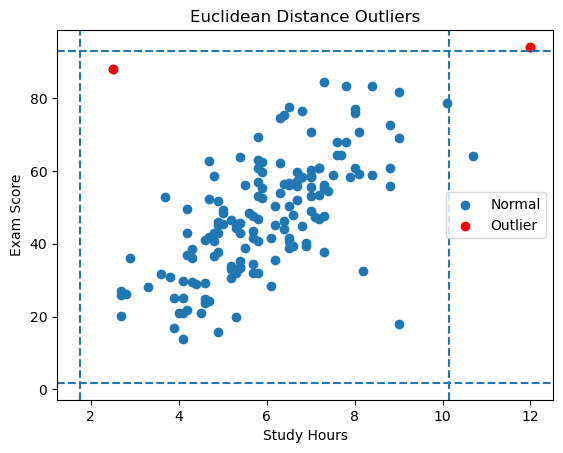

In [15]:
plt.scatter(df["study_hours"], df["exam_score"], label="Normal")
plt.scatter(df.iloc[iqr_eucli]["study_hours"], df.iloc[iqr_eucli]["exam_score"], color="red", label="Outlier")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Euclidean Distance Outliers")

sq1 = df["study_hours"].quantile(0.25)
sq3 = df["study_hours"].quantile(0.75)

eq1 = df["exam_score"].quantile(0.25)
eq3 = df["exam_score"].quantile(0.75)

plt.axvline(sq1 - 1.5 * (sq3 - sq1), linestyle="--")
plt.axvline(sq3 + 1.5 * (sq3 - sq1), linestyle="--")
plt.axhline(eq1 - 1.5 * (eq3 - eq1), linestyle="--")
plt.axhline(eq3 + 1.5 * (eq3 - eq1), linestyle="--")

plt.legend()
plt.show()

The rows flagged in B2 (univariate) are 87 and 150.

 The rows flagged in Euclidean IQR is 150 and 151. 
 
 They are not the same.

.

B.4  Mahalanobis Distance 

In [ ]:
covar = np.cov(df["study_hours"], df["exam_score"])
n
print(covar)

[[  2.61027692  17.06323185]
 [ 17.06323185 280.28733832]]


the off-diagonal value states a positive relationship between the two columns.....coz as study hours increases the marks also increases

In [17]:
X = df[["study_hours", "exam_score"]].values
mean = X.mean(axis=0)
VI = np.linalg.inv(covar)

mahal = np.array([mahalanobis(x, mean, VI) for x in X])
df["mahalanobis"] = mahal

In [ ]:
top5_mahal = df.sort_values(by="mahalanobis", ascending=False).head(5)
print(top5_mahal)

     study_hours  exam_score  mahalanobis
151          2.5        88.0     5.292851
152          9.0        18.0     4.256882
150         12.0        94.0     3.753314
87          10.7        64.2     3.124024
90           8.2        32.4     2.690016


The index 151 and 152 move up in the Mahalanobis ranking compared to Euclidean ranking. 

They moved up because 151 and 152 index are multivariate outliers. Their individual values are not that extreme, so the Euclidean distance sees them as normal and assign them a lower rank.

Also, index 150 moved downward in rank in Mahalanobis because it is a univariate outlier and its high and extreme value matched with the expected positive correlation. So Mahalanobis distance didn't view it as an extreme and its ranks dropped relatively to 151 and 152.

.

In [19]:
maha = df["mahalanobis"].values

top10_maha = np.argsort(maha)[-10:] 
print(len(top10_maha))
print(top10_maha)

10
[ 88  14  41 110   2  90  87 150 152 151]


In [20]:
chi2_thresh = np.sqrt(chi2.ppf(0.975, 2))

scalar_maha = np.where(mahal > chi2_thresh)[0]

print(len(scalar_maha))
print("Indices:", scalar_maha)

4
Indices: [ 87 150 151 152]


In [21]:
Q1 = np.quantile(mahal, 0.25)
Q3 = np.quantile(mahal, 0.75)

IQR = Q3 - Q1
threshold = Q3 + 1.5 * IQR

iqr_maha = np.where(mahal > threshold)[0]

print(len(iqr_maha))
print("Indices:", iqr_maha)

4
Indices: [ 87 150 151 152]


The lowest indices are flagged by the scalar threshold, which is 4, and also by the IQR based technique, which is also 4.

.

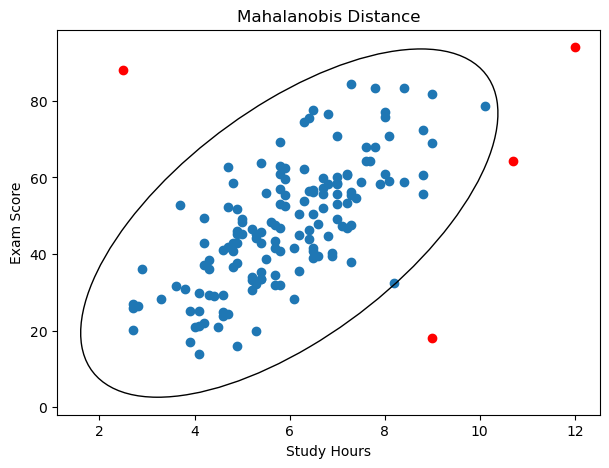

In [22]:
from matplotlib.patches import Ellipse

plt.figure(figsize=(7,5))

mask = mahal > chi2_thresh

plt.scatter(df.loc[~mask, "study_hours"],
            df.loc[~mask, "exam_score"])

plt.scatter(df.loc[mask, "study_hours"],
            df.loc[mask, "exam_score"],
            color="red")

vals, vecs = np.linalg.eigh(covar)
vals = vals[::-1]
vecs = vecs[:, ::-1]

angle = np.degrees(np.arctan2(vecs[1,0], vecs[0,0]))
t = np.sqrt(chi2.ppf(0.975, 2))

ellipse = Ellipse(mean,
                  2*t*np.sqrt(vals[0]),
                  2*t*np.sqrt(vals[1]),
                  angle=angle,
                  fill=False)

plt.gca().add_patch(ellipse)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Mahalanobis Distance")
plt.show()

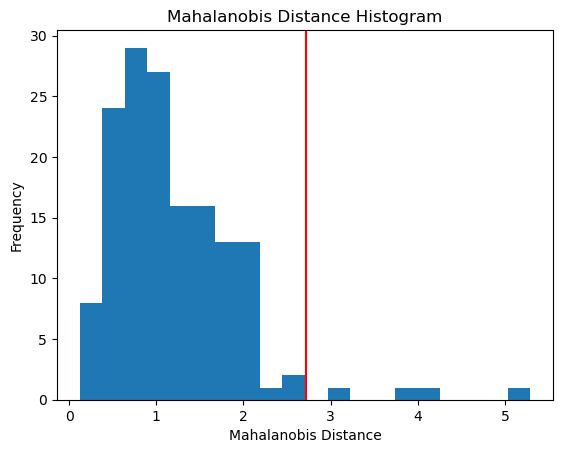

In [23]:
plt.hist(mahal, bins=20)

plt.axvline(chi2_thresh , color="Red")

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("Mahalanobis Distance Histogram")

plt.show()

.

B.5  Comparing the Two Methods 

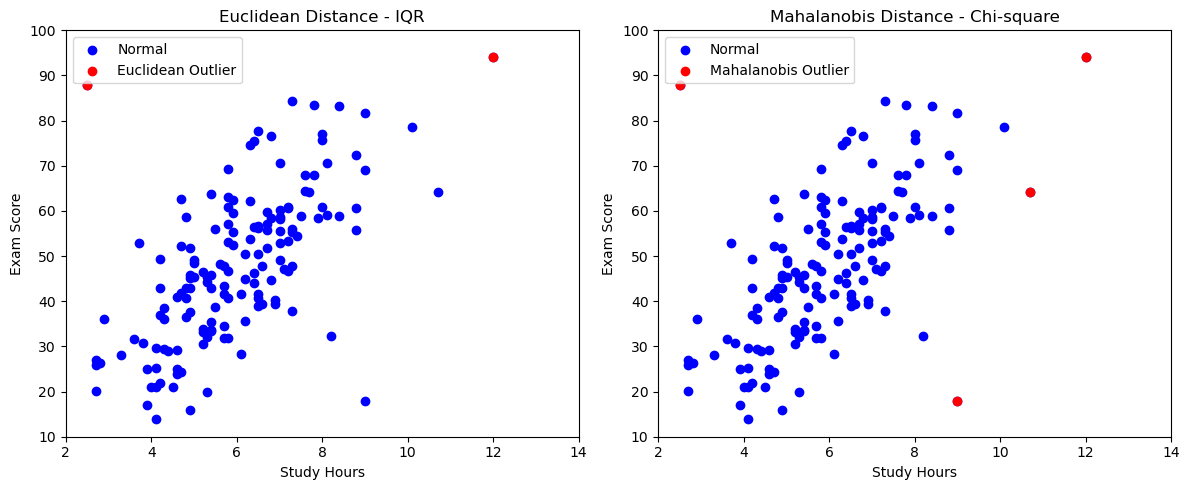

In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.scatter(df["study_hours"], df["exam_score"], color="blue", label="Normal")

plt.scatter(
    df.loc[iqr_eucli, "study_hours"],
    df.loc[iqr_eucli, "exam_score"],
    color="red",
    label="Euclidean Outlier"
)

plt.title("Euclidean Distance - IQR")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.xlim(2, 14)
plt.ylim(10, 100)
plt.legend()


plt.subplot(1, 2, 2)

plt.scatter(df["study_hours"], df["exam_score"], color="blue", label="Normal")

plt.scatter(
    df.loc[scalar_maha, "study_hours"],
    df.loc[scalar_maha, "exam_score"],
    color="red",
    label="Mahalanobis Outlier"
)

plt.title("Mahalanobis Distance - Chi-square")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.xlim(2, 14)
plt.ylim(10, 100)
plt.legend()

plt.tight_layout()
plt.show()

Mahalanobis distance considers the correlation between study hours and exam score, while Euclidean distance does not.

Points B and C do not follow the normal relationship between study hours and exam score, so Mahalanobis gives them a higher distance.
 
Euclidean distance only considers the distance from the centroid and does not consider the correlation between the variables. 

Therefore, Mahalanobis can detect outliers that break the overall relationship between the two variables.

.

In [25]:
both = np.intersect1d(iqr_eucli, iqr_maha)

maha_only = np.setdiff1d(iqr_maha, iqr_eucli)

eucli_only = np.setdiff1d(iqr_eucli, iqr_maha)

all_indices = np.arange(len(df))

neither = np.setdiff1d(all_indices,np.union1d(iqr_eucli, iqr_maha))

print(maha_only)
print(eucli_only)
print(both)
print(neither)

[ 87 152]
[]
[150 151]
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149]


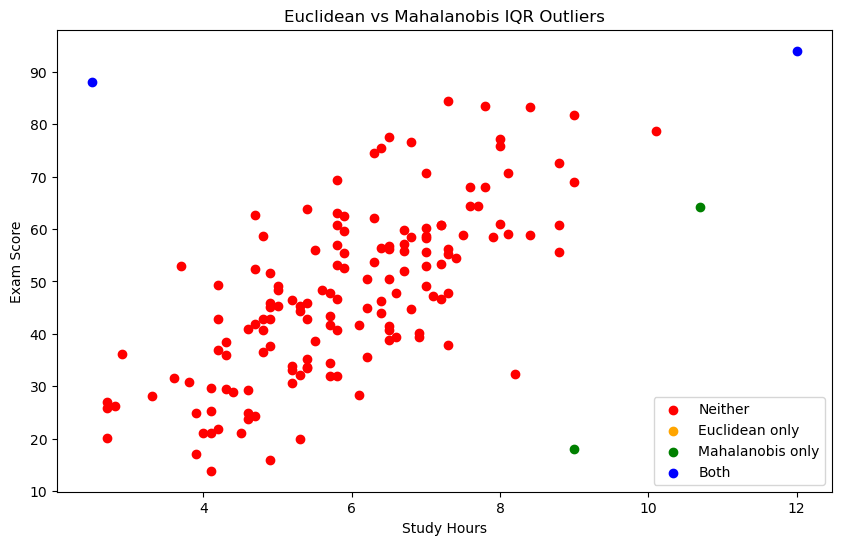

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df.loc[neither, "study_hours"],
    df.loc[neither, "exam_score"],
    color="red",
    label="Neither"
)

plt.scatter(
    df.loc[eucli_only, "study_hours"],
    df.loc[eucli_only, "exam_score"],
    color="orange",
    label="Euclidean only"
)

plt.scatter(
    df.loc[maha_only, "study_hours"],
    df.loc[maha_only, "exam_score"],
    color="green",
    label="Mahalanobis only"
)

plt.scatter(
    df.loc[both, "study_hours"],
    df.loc[both, "exam_score"],
    color="blue",
    label="Both"
)

plt.title("Euclidean vs Mahalanobis IQR Outliers")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.legend()

plt.show()

.

B.6  Take-Home 

In [27]:
project_score = np.clip(
    0.7 * df["exam_score"] + rng.normal(0, 8, 153),0,100
)

df["project_score"] = project_score

In [28]:
three_col = df[["study_hours", "exam_score", "project_score"]].values

print(three_col.shape)

(153, 3)


In [29]:
mean = three_col.mean(axis=0)
cov = np.cov(three_col.T)


In [30]:
VI = np.linalg.inv(cov)

mahal_3 = np.array([
    mahalanobis(x, mean, VI)
    for x in three_col
])

print(mahal_3)

[0.84356979 1.54101452 2.5583163  2.93204136 2.11582106 2.1966865
 1.47957264 0.89529256 2.44079209 0.42152731 1.87807558 1.21270003
 2.05993071 2.06176846 2.34709662 2.12394571 2.86112584 1.29482774
 1.82103376 1.21663692 2.10287827 2.02259873 1.90418387 2.05986469
 1.04647519 0.47920042 0.83159942 0.49214554 2.22389707 2.25275563
 1.75230291 1.03290809 1.58300753 1.5405865  1.81266483 1.26991115
 1.65954198 1.70350393 0.54202191 0.90341949 2.51955322 2.30883306
 1.2008136  1.51661109 0.9887977  1.43201774 2.19619294 1.43187708
 0.88315354 1.57464329 1.37433605 1.221175   0.60330136 1.59591096
 0.83656785 0.67191707 1.35422667 1.49771911 1.00588154 1.44040774
 1.92514078 0.22341437 1.30928944 0.80452152 1.52959013 0.57421302
 1.27981375 1.29635758 0.94806653 2.02785218 0.81929798 1.49833005
 1.38401166 1.52447988 0.74635679 2.12613034 1.37550153 1.86852679
 2.1423189  2.42122196 1.37460561 0.95671959 1.48503868 1.3866532
 1.48747284 2.00805026 2.51408263 3.14913719 2.17161746 0.834713

In [31]:
threshold_3 = np.sqrt(chi2.ppf(0.975, df=3))

flagged_3 = np.where(mahal_3 > threshold_3)[0]

print(flagged_3)


[ 87 150 151 152]


In [32]:
new_flagged = np.setdiff1d(flagged_3, scalar_maha)

print(new_flagged)

[]


no ...there are no newly flagged rows


.

In [33]:
cov_inv = np.linalg.inv(cov)

In [34]:
mahal_numpy = np.sqrt(
    np.sum(
        (three_col - mean) @ cov_inv * (three_col - mean),
        axis=1
    )
)


print(mahal_numpy)

[0.84356979 1.54101452 2.5583163  2.93204136 2.11582106 2.1966865
 1.47957264 0.89529256 2.44079209 0.42152731 1.87807558 1.21270003
 2.05993071 2.06176846 2.34709662 2.12394571 2.86112584 1.29482774
 1.82103376 1.21663692 2.10287827 2.02259873 1.90418387 2.05986469
 1.04647519 0.47920042 0.83159942 0.49214554 2.22389707 2.25275563
 1.75230291 1.03290809 1.58300753 1.5405865  1.81266483 1.26991115
 1.65954198 1.70350393 0.54202191 0.90341949 2.51955322 2.30883306
 1.2008136  1.51661109 0.9887977  1.43201774 2.19619294 1.43187708
 0.88315354 1.57464329 1.37433605 1.221175   0.60330136 1.59591096
 0.83656785 0.67191707 1.35422667 1.49771911 1.00588154 1.44040774
 1.92514078 0.22341437 1.30928944 0.80452152 1.52959013 0.57421302
 1.27981375 1.29635758 0.94806653 2.02785218 0.81929798 1.49833005
 1.38401166 1.52447988 0.74635679 2.12613034 1.37550153 1.86852679
 2.1423189  2.42122196 1.37460561 0.95671959 1.48503868 1.3866532
 1.48747284 2.00805026 2.51408263 3.14913719 2.17161746 0.834713

In [35]:
print(np.allclose(mahal_numpy, mahal_3))

True


yesss the results of the scipy and numpy method both matches 